In [149]:

!pip install ucimlrepo


In [150]:

from ucimlrepo import fetch_ucirepo

# UCI veri setini getir
dataset = fetch_ucirepo(id=856)

# Özellikleri ve hedef değişkeni ayır
X = dataset.data.features
y = dataset.data.targets

# Veriyi birleştir
import pandas as pd
df = pd.concat([X, y], axis=1)

print("Veri boyutu:", df.shape)

display(df.head())


Veri boyutu: (145, 32)


,Student Age,Sex,Graduated high-school type,Scholarship type,Additional work,Regular artistic or sports activity,Do you have a partner,Total salary if available,Transportation to the university,Accomodation type in Cyprus,...,Preparation to midterm exams 1,Preparation to midterm exams 2,Taking notes in classes,Listening in classes,Discussion improves my interest and success in the course,Flip-classroom,Cumulative grade point average in the last semester (/4.00),Expected Cumulative grade point average in the graduation (/4.00),Course ID,OUTPUT Grade
0,2,2,3,3,1,2,2,1,1,1,...,1,1,3,2,1,2,1,1,1,1
1,2,2,3,3,1,2,2,1,1,1,...,1,1,3,2,3,2,2,3,1,1
2,2,2,2,3,2,2,2,2,4,2,...,1,1,2,2,1,1,2,2,1,1
3,1,1,1,3,1,2,1,2,1,2,...,1,2,3,2,2,1,3,2,1,1
4,2,2,1,3,2,2,1,3,1,4,...,2,1,2,2,2,1,2,2,1,1


In [151]:

# Sütun isimleri
print(df.columns.tolist())

# Veri türleri
print(df.info())

# Eksik değerler
print(df.isnull().sum())


['Student Age', 'Sex', 'Graduated high-school type', 'Scholarship type', 'Additional work', 'Regular artistic or sports activity', 'Do you have a partner', 'Total salary if available', 'Transportation to the university', 'Accomodation type in Cyprus', "Mother's education", "Father's education", 'Number of sisters/brothers (if available)', 'Parental status', "Mother's occupation", "Father's occupation", 'Weekly study hours', 'Reading frequency (non-scientific books/journals)', 'Reading frequency (scientific books/journals)', 'Attendance to the seminars/conferences related to the department', 'Impact of your projects/activities on your success', 'Attendance to classes', 'Preparation to midterm exams 1', 'Preparation to midterm exams 2', 'Taking notes in classes', 'Listening in classes', 'Discussion improves my interest and success in the course', 'Flip-classroom', 'Cumulative grade point average in the last semester (/4.00)', 'Expected Cumulative grade point average in the graduation (/4

In [152]:

# Haftalık çalışma süresine göre öğrenci sayıları
print(df["Weekly study hours"].value_counts().sort_index())

# Başarı notlarının dağılımı
print(df["OUTPUT Grade"].value_counts().sort_index())

# Çalışma süresine göre ortalama başarı
print(
    df.groupby("Weekly study hours")["OUTPUT Grade"]
      .mean()
)


Weekly study hours
1    29
2    74
3    30
4     8
5     4
Name: count, dtype: int64
OUTPUT Grade
0     8
1    35
2    24
3    21
4    10
5    17
6    13
7    17
Name: count, dtype: int64
Weekly study hours
1    2.896552
2    3.445946
3    3.266667
4    2.875000
5    2.000000
Name: OUTPUT Grade, dtype: float64


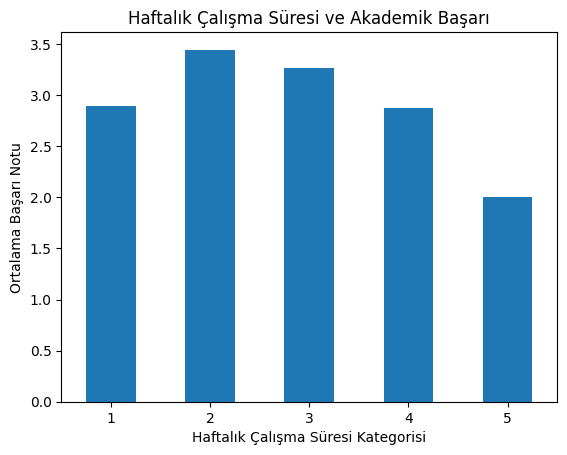

In [153]:

import matplotlib.pyplot as plt

ortalama = df.groupby("Weekly study hours")["OUTPUT Grade"].mean()

ortalama.plot(kind="bar")

plt.title("Haftalık Çalışma Süresi ve Akademik Başarı")
plt.xlabel("Haftalık Çalışma Süresi Kategorisi")
plt.ylabel("Ortalama Başarı Notu")
plt.xticks(rotation=0)
plt.show()


In [154]:

# Her kategorideki öğrenci sayısı
ogrenci_sayisi = df["Weekly study hours"].value_counts().sort_index()

# Her kategorinin başarı ortalaması
basari_ortalamasi = df.groupby("Weekly study hours")["OUTPUT Grade"].mean()

# İki sonucu bir tabloda birleştir
sonuc = pd.DataFrame({
    "Ogrenci Sayisi": ogrenci_sayisi,
    "Ortalama Basari": basari_ortalamasi
})

display(sonuc)


,Ogrenci Sayisi,Ortalama Basari
Weekly study hours,,
1,29,2.896552
2,74,3.445946
3,30,3.266667
4,8,2.875000
5,4,2.000000


In [155]:

from ucimlrepo import fetch_ucirepo
import pandas as pd

dataset = fetch_ucirepo(id=856)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Veri başarıyla yüklendi!")
print(df.shape)


Veri başarıyla yüklendi!
(145, 32)


In [156]:

# İnceleyeceğimiz değişkenler
secilen_veriler = df[[
    "Weekly study hours",
    "Attendance to classes",
    "Preparation to midterm exams 1",
    "Preparation to midterm exams 2",
    "Taking notes in classes",
    "Listening in classes",
    "Cumulative grade point average in the last semester (/4.00)",
    "OUTPUT Grade"
]]

# Spearman korelasyon analizi
korelasyon = secilen_veriler.corr(method="spearman")

display(korelasyon.round(2))


,Weekly study hours,Attendance to classes,Preparation to midterm exams 1,Preparation to midterm exams 2,Taking notes in classes,Listening in classes,Cumulative grade point average in the last semester (/4.00),OUTPUT Grade
Weekly study hours,1.00,-0.13,-0.15,0.35,0.19,-0.10,0.05,-0.01
Attendance to classes,-0.13,1.00,-0.12,-0.19,-0.18,-0.09,-0.18,-0.15
Preparation to midterm exams 1,-0.15,-0.12,1.00,0.18,-0.04,0.04,-0.08,-0.02
Preparation to midterm exams 2,0.35,-0.19,0.18,1.00,0.11,-0.17,0.16,0.06
Taking notes in classes,0.19,-0.18,-0.04,0.11,1.00,-0.01,0.14,0.02
Listening in classes,-0.10,-0.09,0.04,-0.17,-0.01,1.00,0.06,0.10
Cumulative grade point average in the last semester (/4.00),0.05,-0.18,-0.08,0.16,0.14,0.06,1.00,0.35
OUTPUT Grade,-0.01,-0.15,-0.02,0.06,0.02,0.10,0.35,1.00


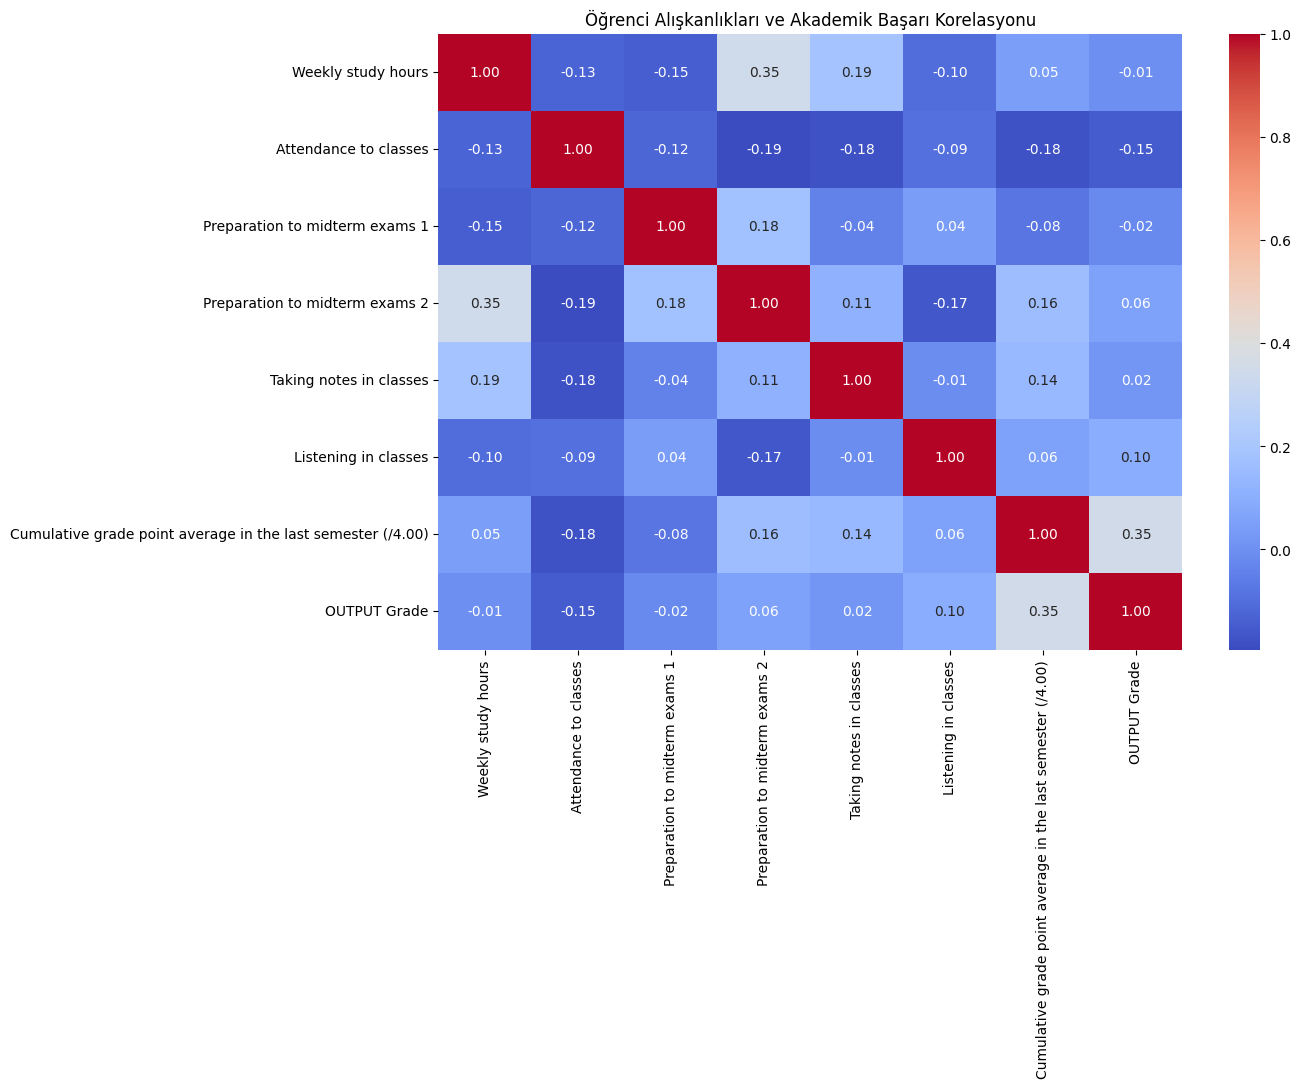

In [157]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    korelasyon,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Öğrenci Alışkanlıkları ve Akademik Başarı Korelasyonu")
plt.show()


In [158]:

# Başarı kategorilerinin dağılımı
print(df["OUTPUT Grade"].value_counts().sort_index())

# Başarı kategorilerinin yüzdesi
print(
    df["OUTPUT Grade"]
    .value_counts(normalize=True)
    .sort_index() * 100
)


OUTPUT Grade
0     8
1    35
2    24
3    21
4    10
5    17
6    13
7    17
Name: count, dtype: int64
OUTPUT Grade
0     5.517241
1    24.137931
2    16.551724
3    14.482759
4     6.896552
5    11.724138
6     8.965517
7    11.724138
Name: proportion, dtype: float64


In [159]:

from sklearn.model_selection import train_test_split

# Modelin kullanacağı özellikler
X = df[[
    "Weekly study hours",
    "Attendance to classes",
    "Preparation to midterm exams 1",
    "Preparation to midterm exams 2",
    "Taking notes in classes",
    "Listening in classes"
]]

# Tahmin etmek istediğimiz sonuç
y = df["OUTPUT Grade"]

# Eğitim ve test verilerini ayır
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)


Eğitim verisi: (116, 6)
Test verisi: (29, 6)


In [160]:

from sklearn.tree import DecisionTreeClassifier

# Modeli oluştur
model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

# Modeli eğit
model.fit(X_train, y_train)

print("Model başarıyla eğitildi!")


Model başarıyla eğitildi!


In [161]:

# Test verileriyle tahmin yap
tahminler = model.predict(X_test)

print("Gerçek değerler:")
print(y_test.values)

print("\nModelin tahminleri:")
print(tahminler)


Gerçek değerler:
[5 5 2 4 1 5 1 1 7 3 7 2 1 7 2 6 3 1 2 6 0 0 3 4 6 3 1 1 2]

Modelin tahminleri:
[1 3 3 1 1 1 1 5 1 5 1 1 1 1 3 3 1 1 3 1 1 1 1 1 3 1 3 1 3]


In [162]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, tahminler))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, tahminler))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test,
    tahminler,
    zero_division=0
))


Accuracy: 0.1724137931034483
Balanced Accuracy: 0.08928571428571429

Sınıflandırma raporu:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.26      0.71      0.38         7
           2       0.00      0.00      0.00         5
           3       0.00      0.00      0.00         4
           4       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         3
           6       0.00      0.00      0.00         3
           7       0.00      0.00      0.00         3

    accuracy                           0.17        29
   macro avg       0.03      0.09      0.05        29
weighted avg       0.06      0.17      0.09        29



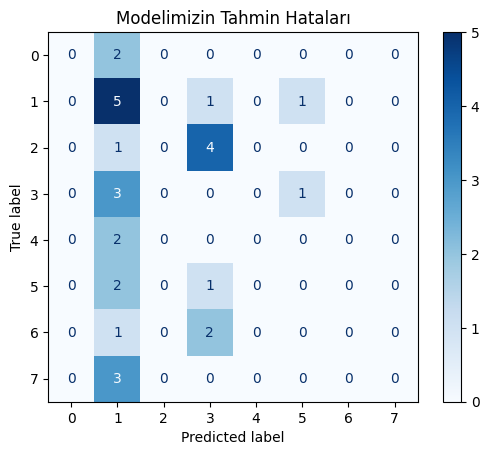

In [163]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, tahminler, labels=range(8))

goruntu = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(8)
)

goruntu.plot(cmap="Blues", values_format="d")

plt.title("Modelimizin Tahmin Hataları")
plt.show()


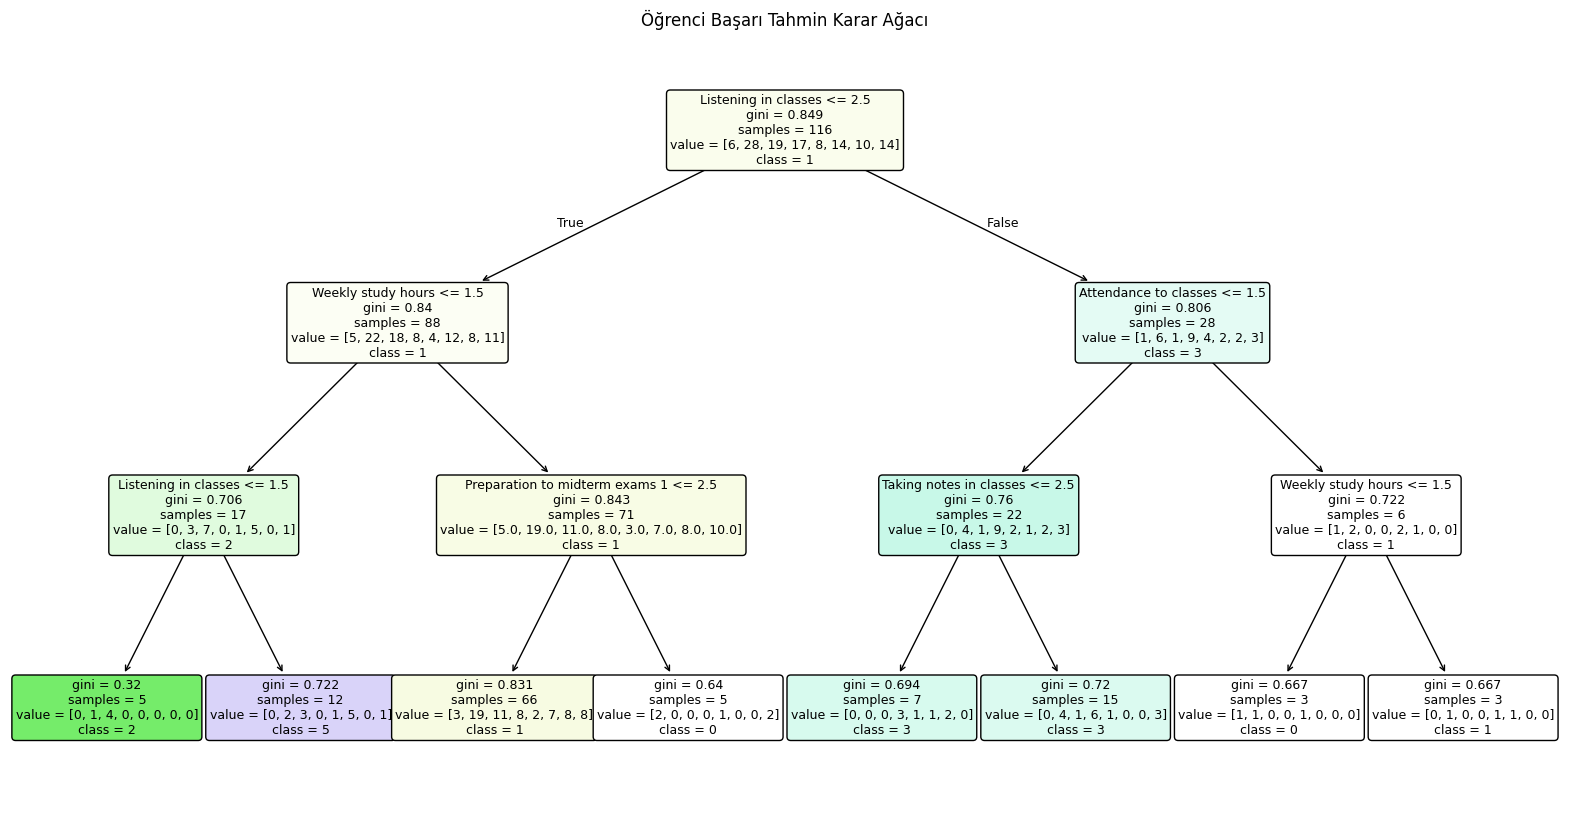

In [164]:

from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(i) for i in model.classes_],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Öğrenci Başarı Tahmin Karar Ağacı")
plt.show()


In [165]:

from sklearn.model_selection import train_test_split

# İlk modelimizde kullandığımız 6 özellik
temel_ozellikler = [
    "Weekly study hours",
    "Attendance to classes",
    "Preparation to midterm exams 1",
    "Preparation to midterm exams 2",
    "Taking notes in classes",
    "Listening in classes"
]

# Yeni ekleyeceğimiz özellik
ek_ozellik = [
    "Cumulative grade point average in the last semester (/4.00)"
]

# Özellik tabloları
X_temel = df[temel_ozellikler]
X_genis = df[temel_ozellikler + ek_ozellik]

# Tahmin hedefimiz
y = df["OUTPUT Grade"]

# Eğitim ve test indekslerini bir kez belirle
egitim_indeksleri, test_indeksleri = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Temel veri
X_train = X_temel.loc[egitim_indeksleri]
X_test = X_temel.loc[test_indeksleri]

# Genişletilmiş veri
X_train_genis = X_genis.loc[egitim_indeksleri]
X_test_genis = X_genis.loc[test_indeksleri]

# Hedef değişkenler
y_train = y.loc[egitim_indeksleri]
y_test = y.loc[test_indeksleri]

print("Eğitim:", X_train.shape)
print("Test:", X_test.shape)
print("Genişletilmiş eğitim:", X_train_genis.shape)


Eğitim: (116, 6)
Test: (29, 6)
Genişletilmiş eğitim: (116, 7)


In [166]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# MODEL 1: Başlangıç karar ağacı
model_1 = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

# MODEL 2: Önceki dönem notu eklenmiş karar ağacı
model_2 = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

# MODEL 3: Daha derin karar ağacı
model_3 = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

# MODEL 4: Random Forest
model_4 = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

print("Dört modelimiz oluşturuldu!")


Dört modelimiz oluşturuldu!


In [167]:

# Model 1: Temel veri
model_1.fit(X_train, y_train)

# Model 2: Genişletilmiş veri
model_2.fit(X_train_genis, y_train)

# Model 3: Derinliği artırılmış ağaç
model_3.fit(X_train, y_train)

# Model 4: Random Forest
model_4.fit(X_train, y_train)

print("Bütün modeller eğitildi!")


Bütün modeller eğitildi!


In [168]:

# Tahminleri oluştur
tahmin_1 = model_1.predict(X_test)
tahmin_2 = model_2.predict(X_test_genis)
tahmin_3 = model_3.predict(X_test)
tahmin_4 = model_4.predict(X_test)

print("Dört modelin tahminleri hazır!")


Dört modelin tahminleri hazır!


In [169]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Modelleri bir listede topla
modeller = [
    ("Başlangıç Decision Tree", tahmin_1),
    ("Ek özellikli Decision Tree", tahmin_2),
    ("Derin Decision Tree", tahmin_3),
    ("Random Forest", tahmin_4)
]

# Sonuçları hesapla
sonuclar = []

for isim, tahmin in modeller:

    accuracy = accuracy_score(y_test, tahmin)

    balanced = balanced_accuracy_score(y_test, tahmin)

    macro_f1 = f1_score(
        y_test,
        tahmin,
        average="macro",
        zero_division=0
    )

    sonuclar.append({
        "Model": isim,
        "Accuracy": round(accuracy, 3),
        "Balanced Accuracy": round(balanced, 3),
        "Macro F1": round(macro_f1, 3)
    })

# Karşılaştırma tablosu
karsilastirma = pd.DataFrame(sonuclar)

display(karsilastirma)


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Başlangıç Decision Tree,0.172,0.089,0.048
1,Ek özellikli Decision Tree,0.276,0.187,0.147
2,Derin Decision Tree,0.138,0.071,0.042
3,Random Forest,0.138,0.085,0.055


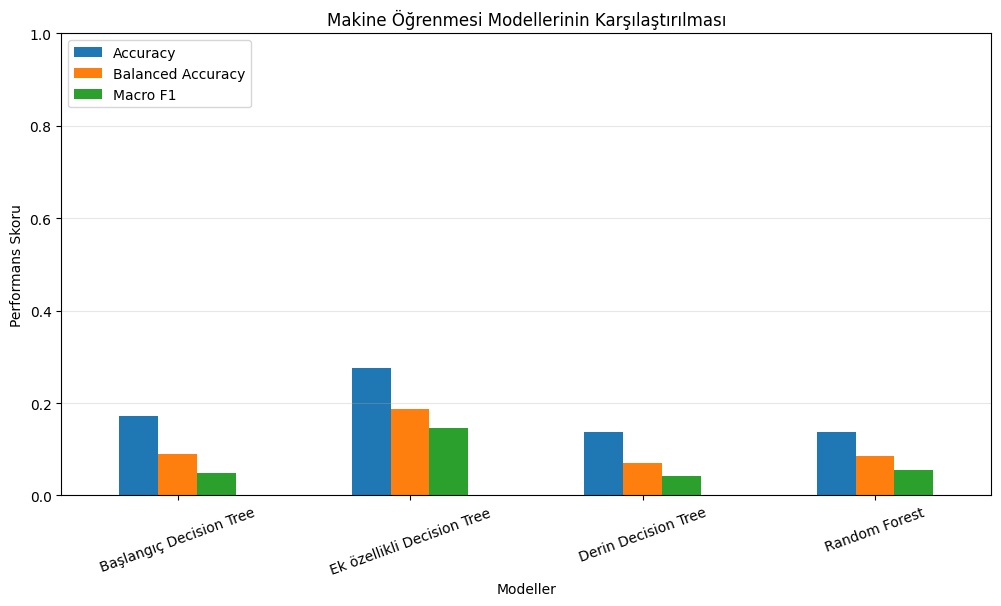

In [170]:

import matplotlib.pyplot as plt

karsilastirma.set_index("Model")[
    ["Accuracy", "Balanced Accuracy", "Macro F1"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Makine Öğrenmesi Modellerinin Karşılaştırılması")
plt.ylabel("Performans Skoru")
plt.xlabel("Modeller")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [171]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier

# 5 parçalı çapraz doğrulama
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Modellerimiz
modeller_cv = {
    "Başlangıç Decision Tree": (model_1, X_temel),
    "Ek özellikli Decision Tree": (model_2, X_genis),
    "Derin Decision Tree": (model_3, X_temel),
    "Random Forest": (model_4, X_temel),
    "Basit referans modeli": (
        DummyClassifier(strategy="most_frequent"),
        X_temel
    )
}

# Ölçüm kriterleri
skorlar = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_sonuclari = []

for isim, (algoritma, ozellikler) in modeller_cv.items():

    sonuc = cross_validate(
        algoritma,
        ozellikler,
        y,
        cv=cv,
        scoring=skorlar
    )

    cv_sonuclari.append({
        "Model": isim,
        "Accuracy": sonuc["test_accuracy"].mean(),
        "Balanced Accuracy": sonuc["test_balanced_accuracy"].mean(),
        "Macro F1": sonuc["test_f1_macro"].mean()
    })

cv_tablo = pd.DataFrame(cv_sonuclari)

display(cv_tablo.round(3))


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Başlangıç Decision Tree,0.221,0.138,0.082
1,Ek özellikli Decision Tree,0.234,0.144,0.100
2,Derin Decision Tree,0.166,0.133,0.109
3,Random Forest,0.221,0.157,0.123
4,Basit referans modeli,0.241,0.125,0.049


,Degisken,Onem
5,Listening in classes,0.257583
0,Weekly study hours,0.234983
1,Attendance to classes,0.154552
2,Preparation to midterm exams 1,0.152732
4,Taking notes in classes,0.143922
3,Preparation to midterm exams 2,0.056228


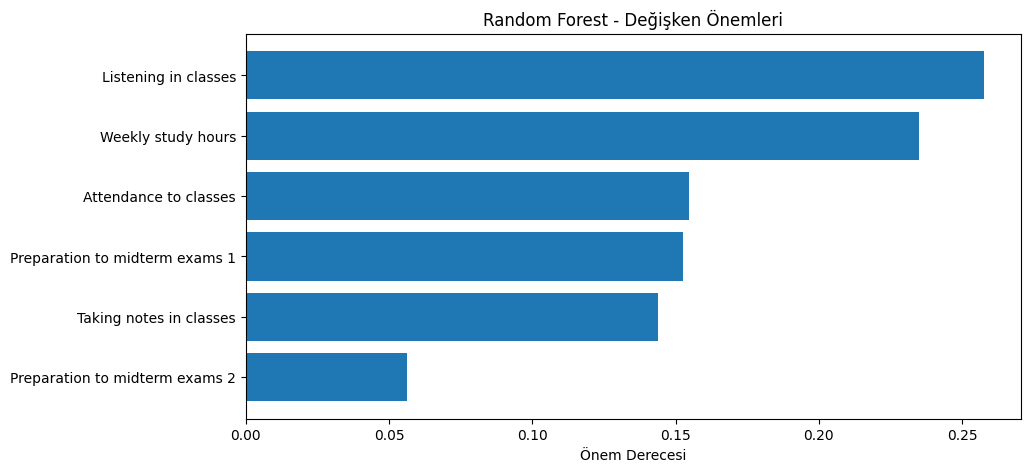

In [172]:

import pandas as pd
import matplotlib.pyplot as plt

# Random Forest değişken önemleri
onem = pd.DataFrame({
    "Degisken": X_train.columns,
    "Onem": model_4.feature_importances_
})

# Önem derecesine göre sırala
onem = onem.sort_values(
    by="Onem",
    ascending=False
)

display(onem)

# Grafik oluştur
plt.figure(figsize=(10, 5))

plt.barh(
    onem["Degisken"],
    onem["Onem"]
)

plt.xlabel("Önem Derecesi")
plt.title("Random Forest - Değişken Önemleri")
plt.gca().invert_yaxis()

plt.show()


In [173]:

# Dersleri dinleme düzeyine göre başarı
dinleme_analizi = df.groupby(
    "Listening in classes"
)["OUTPUT Grade"].agg(
    ["count", "mean"]
)

print("Dersleri dinleme analizi:")
display(dinleme_analizi)

# Haftalık çalışma süresine göre başarı
calisma_analizi = df.groupby(
    "Weekly study hours"
)["OUTPUT Grade"].agg(
    ["count", "mean"]
)

print("Haftalık çalışma analizi:")
display(calisma_analizi)


Dersleri dinleme analizi:


,count,mean
Listening in classes,,
1,29,2.827586
2,79,3.291139
3,37,3.405405


Haftalık çalışma analizi:


,count,mean
Weekly study hours,,
1,29,2.896552
2,74,3.445946
3,30,3.266667
4,8,2.875000
5,4,2.000000


In [174]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold

# Kategorik değişkenler
kategorik = [
    "Preparation to midterm exams 1",
    "Preparation to midterm exams 2",
    "Impact of your projects/activities on your success",
    "Flip-classroom"
]

# Çalışma alışkanlıkları
sayisal = [
    "Weekly study hours",
    "Reading frequency (non-scientific books/journals)",
    "Reading frequency (scientific books/journals)",
    "Attendance to classes",
    "Taking notes in classes",
    "Listening in classes",
    "Discussion improves my interest and success in the course"
]

# Kullanacağımız özellikler
ozellikler = kategorik + sayisal

X_yeni = df[ozellikler]
y = df["OUTPUT Grade"]

# Kategorik verileri dönüştür
on_isleme = ColumnTransformer([
    ("kategori", OneHotEncoder(handle_unknown="ignore"), kategorik),
    ("sayisal", "passthrough", sayisal)
])

# Yeni Random Forest
yeni_model = Pipeline([
    ("on_isleme", on_isleme),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    ))
])

# 5 katlı çapraz doğrulama
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

sonuc = cross_validate(
    yeni_model,
    X_yeni,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1_macro": "f1_macro"
    }
)

print("Accuracy:", sonuc["test_accuracy"].mean())
print("Balanced Accuracy:", sonuc["test_balanced_accuracy"].mean())
print("Macro F1:", sonuc["test_f1_macro"].mean())


Accuracy: 0.2206896551724138
Balanced Accuracy: 0.13607142857142857
Macro F1: 0.09412792681175035


In [175]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate, KFold
from sklearn.dummy import DummyRegressor

# Özelliklerimizi belirleyelim
X_reg = df[[
    "Weekly study hours",
    "Attendance to classes",
    "Preparation to midterm exams 1",
    "Preparation to midterm exams 2",
    "Taking notes in classes",
    "Listening in classes",
    "Cumulative grade point average in the last semester (/4.00)"
]]

y_reg = df["OUTPUT Grade"]

# Random Forest Regression
reg_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

# Basit karşılaştırma modeli
baseline = DummyRegressor(strategy="mean")

# 5 katlı çapraz doğrulama
cv_reg = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Modelleri değerlendirelim
for isim, algoritma in [
    ("Random Forest Regression", reg_model),
    ("Basit Ortalama Modeli", baseline)
]:

    sonuc = cross_validate(
        algoritma,
        X_reg,
        y_reg,
        cv=cv_reg,
        scoring=["neg_mean_absolute_error",
                 "neg_root_mean_squared_error",
                 "r2"]
    )

    print("\n", isim)
    print("MAE:", round(-sonuc["test_neg_mean_absolute_error"].mean(), 3))
    print("RMSE:", round(-sonuc["test_neg_root_mean_squared_error"].mean(), 3))
    print("R2:", round(sonuc["test_r2"].mean(), 3))



 Random Forest Regression
MAE: 1.8
RMSE: 2.175
R2: -0.05

 Basit Ortalama Modeli
MAE: 1.92
RMSE: 2.2
R2: -0.075


In [176]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import make_scorer
import numpy as np

# Önceden hazırladığımız X_yeni ve y değişkenlerini kullanıyoruz

siniflandirici = Pipeline([
    ("on_isleme", on_isleme),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    ))
])

referans = DummyClassifier(strategy="most_frequent")

# Kategoriler arasındaki mutlak hatayı ölç
ordinal_mae = make_scorer(
    lambda gercek, tahmin: np.mean(
        np.abs(gercek - tahmin)
    ),
    greater_is_better=False
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for isim, model in [
    ("Random Forest Classifier", siniflandirici),
    ("Basit Referans", referans)
]:

    sonuc = cross_validate(
        model,
        X_yeni,
        y,
        cv=cv,
        scoring={"ordinal_mae": ordinal_mae}
    )

    print(isim, "MAE:", round(
        -sonuc["test_ordinal_mae"].mean(), 3
    ))


Random Forest Classifier MAE: 2.221
Basit Referans MAE: 2.338


In [177]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 5 katlı çapraz doğrulama
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Denenecek model ayarları
parametreler = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, None],
    "min_samples_leaf": [2, 3, 5],
    "class_weight": [None, "balanced"]
}

# Başarı ölçütleri
arama = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=parametreler,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "f1_macro": "f1_macro"
    },
    refit="f1_macro",
    cv=cv,
    n_jobs=-1
)

# Modeli eğit ve en iyi ayarları bul
arama.fit(X, y)

print("En iyi parametreler:")
print(arama.best_params_)

print("\nEn iyi Macro F1:")
print(arama.best_score_)

print("\nDiğer başarı ölçütleri:")
print(arama.cv_results_["mean_test_accuracy"][
    arama.best_index_
])
print(arama.cv_results_["mean_test_balanced_accuracy"][
    arama.best_index_
])


En iyi parametreler:
{'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}

En iyi Macro F1:
0.16205354286236637

Diğer başarı ölçütleri:
0.1793103448275862
0.1800595238095238


SINIF BAZLI PERFORMANS
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         8
           1       0.18      0.06      0.09        35
           2       0.22      0.21      0.21        24
           3       0.21      0.24      0.22        21
           4       0.00      0.00      0.00        10
           5       0.20      0.29      0.24        17
           6       0.29      0.46      0.35        13
           7       0.12      0.18      0.15        17

    accuracy                           0.18       145
   macro avg       0.15      0.18      0.16       145
weighted avg       0.17      0.18      0.17       145



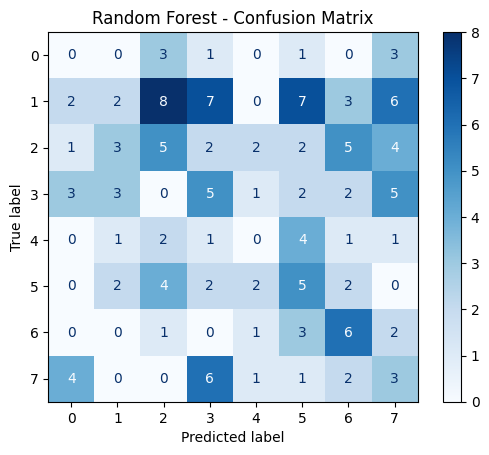

In [178]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# En iyi modelin çapraz doğrulama tahminleri
tahminler = cross_val_predict(
    arama.best_estimator_,
    X,
    y,
    cv=cv
)

# Her not sınıfı için performans
print("SINIF BAZLI PERFORMANS")
print(classification_report(
    y,
    tahminler,
    labels=[0, 1, 2, 3, 4, 5, 6, 7],
    zero_division=0
))

# Karmaşıklık matrisi
ConfusionMatrixDisplay.from_predictions(
    y,
    tahminler,
    labels=[0, 1, 2, 3, 4, 5, 6, 7],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()


In [179]:
for sutun in df.columns:
    print(sutun)

Student Age
Sex
Graduated high-school type
Scholarship type
Additional work
Regular artistic or sports activity
Do you have a partner
Total salary if available
Transportation to the university
Accomodation type in Cyprus
Mother's education
Father's education
Number of sisters/brothers (if available)
Parental status
Mother's occupation
Father's occupation
Weekly study hours
Reading frequency (non-scientific books/journals)
Reading frequency (scientific books/journals)
Attendance to the seminars/conferences related to the department
Impact of your projects/activities on your success
Attendance to classes
Preparation to midterm exams 1
Preparation to midterm exams 2
Taking notes in classes
Listening in classes
Discussion improves my interest and success in the course
Flip-classroom
Cumulative grade point average in the last semester (/4.00)
Expected Cumulative grade point average in the graduation (/4.00)
Course ID
OUTPUT Grade


In [180]:

# Her sütunun kaç farklı değer içerdiğini inceleyelim
for sutun in df.columns:
    print(f"\n{sutun}")
    print("Farklı değer sayısı:", df[sutun].nunique())
    print("Değerler:", sorted(df[sutun].unique()))



Student Age
Farklı değer sayısı: 3
Değerler: [np.int64(1), np.int64(2), np.int64(3)]

Sex
Farklı değer sayısı: 2
Değerler: [np.int64(1), np.int64(2)]

Graduated high-school type
Farklı değer sayısı: 3
Değerler: [np.int64(1), np.int64(2), np.int64(3)]

Scholarship type
Farklı değer sayısı: 5
Değerler: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Additional work
Farklı değer sayısı: 2
Değerler: [np.int64(1), np.int64(2)]

Regular artistic or sports activity
Farklı değer sayısı: 2
Değerler: [np.int64(1), np.int64(2)]

Do you have a partner
Farklı değer sayısı: 2
Değerler: [np.int64(1), np.int64(2)]

Total salary if available
Farklı değer sayısı: 5
Değerler: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Transportation to the university
Farklı değer sayısı: 4
Değerler: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Accomodation type in Cyprus
Farklı değer sayısı: 4
Değerler: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Mother's edu

In [181]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import pandas as pd

# A: Çalışma alışkanlıkları
alisKanliklari = [
    "Weekly study hours",
    "Reading frequency (non-scientific books/journals)",
    "Reading frequency (scientific books/journals)",
    "Attendance to the seminars/conferences related to the department",
    "Impact of your projects/activities on your success",
    "Attendance to classes",
    "Preparation to midterm exams 1",
    "Preparation to midterm exams 2",
    "Taking notes in classes",
    "Listening in classes",
    "Discussion improves my interest and success in the course",
    "Flip-classroom"
]

# B: Çalışma alışkanlıkları + önceki dönem not ortalaması
akademikGecmis = alisKanliklari + [
    "Cumulative grade point average in the last semester (/4.00)"
]

# C: Genişletilmiş öğrenci profili
genisProfil = [
    sutun for sutun in df.columns
    if sutun not in [
        "OUTPUT Grade",
        "Expected Cumulative grade point average in the graduation (/4.00)",
        "Course ID"
    ]
]

# Hedef değişken
y = df["OUTPUT Grade"]

# Aynı çapraz doğrulama yöntemi
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

deneyler = {
    "A - Çalışma alışkanlıkları": alisKanliklari,
    "B - Alışkanlıklar + akademik geçmiş": akademikGecmis,
    "C - Genişletilmiş profil": genisProfil
}

sonuclar = []

for deneyAdi, ozellikler in deneyler.items():

    X_deney = df[ozellikler]

    model = Pipeline([
        ("kodlama", OneHotEncoder(handle_unknown="ignore")),
        ("siniflandirici", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ])

    skorlar = cross_validate(
        model,
        X_deney,
        y,
        cv=cv,
        scoring=[
            "accuracy",
            "balanced_accuracy",
            "f1_macro"
        ]
    )

    sonuclar.append({
        "Deney": deneyAdi,
        "Özellik sayısı": len(ozellikler),
        "Accuracy": skorlar["test_accuracy"].mean(),
        "Balanced Accuracy": skorlar["test_balanced_accuracy"].mean(),
        "Macro F1": skorlar["test_f1_macro"].mean()
    })

tablo = pd.DataFrame(sonuclar)
print(tablo.round(3))


                                 Deney  Özellik sayısı  Accuracy  \
0           A - Çalışma alışkanlıkları              12     0.152   
1  B - Alışkanlıklar + akademik geçmiş              13     0.221   
2             C - Genişletilmiş profil              29     0.283   

   Balanced Accuracy  Macro F1  
0              0.142     0.127  
1              0.177     0.169  
2              0.252     0.232  


In [182]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

X_c = df[genisProfil]
y = df["OUTPUT Grade"]

# Genişletilmiş profil modeli
rf_model = Pipeline([
    ("kodlama", OneHotEncoder(handle_unknown="ignore")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ))
])

# Basit referans modeli
dummy_model = DummyClassifier(strategy="most_frequent")

olcutler = [
    "accuracy",
    "balanced_accuracy",
    "f1_macro"
]

# İki modeli aynı katlarda değerlendir
rf_skor = cross_validate(
    rf_model, X_c, y, cv=cv,
    scoring=olcutler
)

dummy_skor = cross_validate(
    dummy_model, X_c, y, cv=cv,
    scoring=olcutler
)

karsilastirma = pd.DataFrame({
    "Model": ["Random Forest", "Basit Referans"],
    "Accuracy": [
        rf_skor["test_accuracy"].mean(),
        dummy_skor["test_accuracy"].mean()
    ],
    "Balanced Accuracy": [
        rf_skor["test_balanced_accuracy"].mean(),
        dummy_skor["test_balanced_accuracy"].mean()
    ],
    "Macro F1": [
        rf_skor["test_f1_macro"].mean(),
        dummy_skor["test_f1_macro"].mean()
    ]
})

print(karsilastirma.round(3))


            Model  Accuracy  Balanced Accuracy  Macro F1
0   Random Forest     0.283              0.252     0.232
1  Basit Referans     0.241              0.125     0.049


In [183]:

from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

X_c = df[genisProfil]
y = df["OUTPUT Grade"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model = Pipeline([
    ("kodlama", OneHotEncoder(handle_unknown="ignore")),
    ("siniflandirici", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ))
])

# Her kat için ayrı önem analizi
onemler = []

for egitim, test in cv.split(X_c, y):

    X_train = X_c.iloc[egitim]
    X_test = X_c.iloc[test]
    y_train = y.iloc[egitim]
    y_test = y.iloc[test]

    model.fit(X_train, y_train)

    sonuc = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=10,
        random_state=42
    )

    onemler.append(sonuc.importances_mean)

# Beş katın ortalamasını hesapla
onem_tablosu = pd.DataFrame(
    onemler,
    columns=X_c.columns
)

ortalama_onem = onem_tablosu.mean().sort_values(
    ascending=False
)

print("EN ÖNEMLİ 10 DEĞİŞKEN")
print(ortalama_onem.head(10).round(4))


EN ÖNEMLİ 10 DEĞİŞKEN
Scholarship type                                                    0.0435
Sex                                                                 0.0401
Mother's education                                                  0.0278
Accomodation type in Cyprus                                         0.0242
Cumulative grade point average in the last semester (/4.00)         0.0232
Weekly study hours                                                  0.0198
Student Age                                                         0.0180
Impact of your projects/activities on your success                  0.0168
Attendance to the seminars/conferences related to the department    0.0129
Flip-classroom                                                      0.0122
dtype: float64


In [184]:

from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Hassas veya sosyoekonomik açıdan dikkat gerektiren değişkenleri çıkar
cikarilacaklar = [
    "Sex",
    "Scholarship type",
    "Mother's education"
]

daha_dar_profil = [
    sutun for sutun in genisProfil
    if sutun not in cikarilacaklar
]

deneyler = {
    "Tüm değişkenler": genisProfil,
    "Seçilmiş değişkenler çıkarıldı": daha_dar_profil
}

sonuclar = []

for ad, ozellikler in deneyler.items():

    model = Pipeline([
        ("kodlama", OneHotEncoder(handle_unknown="ignore")),
        ("siniflandirici", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ])

    skor = cross_validate(
        model,
        df[ozellikler],
        y,
        cv=cv,
        scoring=[
            "accuracy",
            "balanced_accuracy",
            "f1_macro"
        ]
    )

    sonuclar.append({
        "Model": ad,
        "Özellik sayısı": len(ozellikler),
        "Accuracy": skor["test_accuracy"].mean(),
        "Balanced Accuracy": skor["test_balanced_accuracy"].mean(),
        "Macro F1": skor["test_f1_macro"].mean()
    })

print(pd.DataFrame(sonuclar).round(3))


                            Model  Özellik sayısı  Accuracy  \
0                 Tüm değişkenler              29     0.283   
1  Seçilmiş değişkenler çıkarıldı              26     0.207   

   Balanced Accuracy  Macro F1  
0              0.252     0.232  
1              0.159     0.144  


In [185]:

cikarilacaklar = [
    "Sex",
    "Scholarship type",
    "Mother's education"
]

sonuclar = []

# Önce tüm değişkenlerle başlangıç sonucu
deneyler = {
    "Tüm değişkenler": genisProfil
}

# Her değişkeni tek tek çıkar
for sutun in cikarilacaklar:
    deneyler[f"{sutun} çıkarıldı"] = [
        x for x in genisProfil if x != sutun
    ]

for ad, ozellikler in deneyler.items():

    model = Pipeline([
        ("kodlama", OneHotEncoder(handle_unknown="ignore")),
        ("siniflandirici", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ])

    skor = cross_validate(
        model,
        df[ozellikler],
        y,
        cv=cv,
        scoring=["accuracy", "balanced_accuracy", "f1_macro"]
    )

    sonuclar.append({
        "Deney": ad,
        "Accuracy": skor["test_accuracy"].mean(),
        "Balanced Accuracy": skor["test_balanced_accuracy"].mean(),
        "Macro F1": skor["test_f1_macro"].mean()
    })

print(pd.DataFrame(sonuclar).round(3))


                          Deney  Accuracy  Balanced Accuracy  Macro F1
0               Tüm değişkenler     0.283              0.252     0.232
1                 Sex çıkarıldı     0.228              0.184     0.164
2    Scholarship type çıkarıldı     0.228              0.215     0.193
3  Mother's education çıkarıldı     0.248              0.205     0.185


In [186]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

X_c = df[genisProfil]
y = df["OUTPUT Grade"]

model = Pipeline([
    ("kodlama", OneHotEncoder(handle_unknown="ignore")),
    ("siniflandirici", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ))
])

# Her öğrenci için çapraz doğrulama tahmini
tahminler = cross_val_predict(
    model, X_c, y, cv=cv
)

# Cinsiyet gruplarına göre performans
sonuclar = []

for grup in sorted(df["Sex"].unique()):

    maske = df["Sex"] == grup

    gercek = y[maske]
    tahmin = tahminler[maske]

    sonuclar.append({
        "Sex kodu": grup,
        "Öğrenci sayısı": maske.sum(),
        "Accuracy": accuracy_score(gercek, tahmin),
        "Balanced Accuracy": balanced_accuracy_score(
            gercek, tahmin
        ),
        "Macro F1": f1_score(
            gercek, tahmin,
            average="macro",
            zero_division=0
        )
    })

print(pd.DataFrame(sonuclar).round(3))


   Sex kodu  Öğrenci sayısı  Accuracy  Balanced Accuracy  Macro F1
0         1              58     0.207              0.184     0.154
1         2              87     0.333              0.286     0.244


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [187]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd

sonuclar = []

tum_siniflar = sorted(y.unique())

for grup in sorted(df["Sex"].unique()):
    maske = df["Sex"] == grup

    gercek = y[maske]
    tahmin = tahminler[maske]

    # Gerçek veride bulunan sınıflar
    mevcut_siniflar = np.unique(gercek)

    # Balanced Accuracy: yalnızca gerçek veride bulunan sınıflar
    balanced_acc = recall_score(
        gercek,
        tahmin,
        labels=mevcut_siniflar,
        average="macro",
        zero_division=0
    )

    # Her iki grup için aynı 8 sınıf üzerinden Macro F1
    macro_f1 = f1_score(
        gercek,
        tahmin,
        labels=tum_siniflar,
        average="macro",
        zero_division=0
    )

    sonuclar.append({
        "Sex kodu": grup,
        "Öğrenci sayısı": len(gercek),
        "Accuracy": accuracy_score(gercek, tahmin),
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1,
        "Gerçekte bulunan not sınıfı": len(mevcut_siniflar)
    })

print(pd.DataFrame(sonuclar).round(3))

   Sex kodu  Öğrenci sayısı  Accuracy  Balanced Accuracy  Macro F1  \
0         1              58     0.207              0.184     0.154   
1         2              87     0.333              0.286     0.244   

   Gerçekte bulunan not sınıfı  
0                            7  
1                            7  


In [188]:
not_dagilimi = pd.crosstab(
    df["Sex"],
    df["OUTPUT Grade"],
    normalize="index"
) * 100

print(not_dagilimi.round(1))

OUTPUT Grade     0     1     2     3    4     5     6     7
Sex                                                        
1             13.8  27.6  20.7  12.1  8.6  10.3   6.9   0.0
2              0.0  21.8  13.8  16.1  5.7  12.6  10.3  19.5


In [189]:
# Cinsiyet değişkenini çıkarıyoruz
cinsiyetsiz_profil = [
    sutun for sutun in genisProfil
    if sutun != "Sex"
]

X_cinsiyetsiz = df[cinsiyetsiz_profil]

model_cinsiyetsiz = Pipeline([
    ("kodlama", OneHotEncoder(handle_unknown="ignore")),
    ("siniflandirici", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ))
])

tahmin_cinsiyetsiz = cross_val_predict(
    model_cinsiyetsiz,
    X_cinsiyetsiz,
    y,
    cv=cv
)

sonuclar = []

for grup in sorted(df["Sex"].unique()):
    maske = df["Sex"] == grup

    sonuclar.append({
        "Sex kodu": grup,
        "Öğrenci sayısı": maske.sum(),
        "Accuracy": accuracy_score(y[maske], tahmin_cinsiyetsiz[maske]),
        "Macro F1": f1_score(
            y[maske],
            tahmin_cinsiyetsiz[maske],
            labels=sorted(y.unique()),
            average="macro",
            zero_division=0
        )
    })

print(pd.DataFrame(sonuclar).round(3))

   Sex kodu  Öğrenci sayısı  Accuracy  Macro F1
0         1              58     0.190     0.165
1         2              87     0.253     0.182


In [190]:

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# 29 değişkenli genişletilmiş profil
X_c = df[genisProfil]
y = df["OUTPUT Grade"]

# Model
pipeline = Pipeline([
    ("kodlama", OneHotEncoder(handle_unknown="ignore")),
    ("siniflandirici", RandomForestClassifier(
        random_state=42
    ))
])

# Denenecek parametreler
parametreler = {
    "siniflandirici__n_estimators": [100, 200],
    "siniflandirici__max_depth": [3, 5, None],
    "siniflandirici__min_samples_leaf": [2, 3, 5],
    "siniflandirici__class_weight": [None, "balanced"]
}

# İç doğrulama: parametre seçimi
ic_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

arama = GridSearchCV(
    estimator=pipeline,
    param_grid=parametreler,
    scoring="f1_macro",
    cv=ic_cv,
    n_jobs=-1
)

# Dış doğrulama: bağımsız performans değerlendirmesi
dis_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# İç içe çapraz doğrulama
sonuc = cross_validate(
    arama,
    X_c,
    y,
    cv=dis_cv,
    scoring=[
        "accuracy",
        "balanced_accuracy",
        "f1_macro"
    ]
)

print("NESTED CROSS VALIDATION SONUÇLARI")
print("Accuracy:", round(sonuc["test_accuracy"].mean(), 3))
print("Balanced Accuracy:", round(
    sonuc["test_balanced_accuracy"].mean(), 3
))
print("Macro F1:", round(
    sonuc["test_f1_macro"].mean(), 3
))

# Her öğrenci için dış katlardan tahmin üret
tahminler_nested = cross_val_predict(
    arama,
    X_c,
    y,
    cv=dis_cv
)

print("\nTahmin sayısı:", len(tahminler_nested))


NESTED CROSS VALIDATION SONUÇLARI
Accuracy: 0.283
Balanced Accuracy: 0.287
Macro F1: 0.247

Tahmin sayısı: 145


In [191]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score
)
import numpy as np
import pandas as pd

# Basit referans modeli
dummy = DummyClassifier(strategy="most_frequent")

dummy_sonuc = cross_validate(
    dummy,
    X_c,
    y,
    cv=dis_cv,
    scoring=[
        "accuracy",
        "balanced_accuracy",
        "f1_macro"
    ]
)

# Nested CV ve Dummy modelini aynı tabloda karşılaştır
karsilastirma = pd.DataFrame({
    "Model": ["Nested Random Forest", "Dummy Baseline"],
    "Accuracy": [
        sonuc["test_accuracy"].mean(),
        dummy_sonuc["test_accuracy"].mean()
    ],
    "Balanced Accuracy": [
        sonuc["test_balanced_accuracy"].mean(),
        dummy_sonuc["test_balanced_accuracy"].mean()
    ],
    "Macro F1": [
        sonuc["test_f1_macro"].mean(),
        dummy_sonuc["test_f1_macro"].mean()
    ]
})

print(karsilastirma.round(3))

# Nested CV tahminleriyle cinsiyet grubu analizi
grup_sonuclari = []

tum_siniflar = sorted(y.unique())

for grup in sorted(df["Sex"].unique()):
    maske = df["Sex"] == grup
    gercek = y[maske]
    tahmin = tahminler_nested[maske]

    mevcut_siniflar = np.unique(gercek)

    grup_sonuclari.append({
        "Sex": grup,
        "Öğrenci sayısı": len(gercek),
        "Accuracy": accuracy_score(gercek, tahmin),
        "Balanced Accuracy": recall_score(
            gercek,
            tahmin,
            labels=mevcut_siniflar,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            gercek,
            tahmin,
            labels=tum_siniflar,
            average="macro",
            zero_division=0
        )
    })

print("\nNESTED CV CİNSİYET GRUBU SONUÇLARI")
print(pd.DataFrame(grup_sonuclari).round(3))

# Katlar arasındaki performans değişkenliği
print("\nKATLAR ARASI STANDART SAPMA")
print("Accuracy:", round(sonuc["test_accuracy"].std(), 3))
print("Balanced Accuracy:", round(
    sonuc["test_balanced_accuracy"].std(), 3
))
print("Macro F1:", round(sonuc["test_f1_macro"].std(), 3))


                  Model  Accuracy  Balanced Accuracy  Macro F1
0  Nested Random Forest     0.283              0.287     0.247
1        Dummy Baseline     0.241              0.125     0.049

NESTED CV CİNSİYET GRUBU SONUÇLARI
   Sex  Öğrenci sayısı  Accuracy  Balanced Accuracy  Macro F1
0    1              58     0.190              0.172      0.13
1    2              87     0.345              0.293      0.25

KATLAR ARASI STANDART SAPMA
Accuracy: 0.099
Balanced Accuracy: 0.111
Macro F1: 0.091


In [192]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

not_isimleri = [
    "FF", "DD", "DC", "CC",
    "CB", "BB", "BA", "AA"
]

siniflar = list(range(8))

# Her not sınıfının performansı
rapor = classification_report(
    y,
    tahminler_nested,
    labels=siniflar,
    target_names=not_isimleri,
    output_dict=True,
    zero_division=0
)

rapor_df = pd.DataFrame(rapor).T

print("SINIF BAZLI PERFORMANS")
print(rapor_df.round(3))

# Karmaşıklık matrisi
matris = confusion_matrix(
    y,
    tahminler_nested,
    labels=siniflar
)

matris_df = pd.DataFrame(
    matris,
    index=not_isimleri,
    columns=not_isimleri
)

print("\nCONFUSION MATRIX")
print(matris_df)


SINIF BAZLI PERFORMANS
              precision  recall  f1-score  support
FF                0.278   0.625     0.385    8.000
DD                0.375   0.257     0.305   35.000
DC                0.304   0.292     0.298   24.000
CC                0.333   0.286     0.308   21.000
CB                0.000   0.000     0.000   10.000
BB                0.176   0.176     0.176   17.000
BA                0.091   0.077     0.083   13.000
AA                0.400   0.588     0.476   17.000
accuracy          0.283   0.283     0.283    0.283
macro avg         0.245   0.288     0.254  145.000
weighted avg      0.280   0.283     0.273  145.000

CONFUSION MATRIX
    FF  DD  DC  CC  CB  BB  BA  AA
FF   5   1   0   0   1   0   0   1
DD   4   9   5   6   1   4   3   3
DC   2   3   7   1   4   1   1   5
CC   3   2   4   6   1   3   1   1
CB   1   1   1   3   0   1   1   2
BB   0   3   3   1   2   3   4   1
BA   2   2   2   0   0   4   1   2
AA   1   3   1   1   0   1   0  10


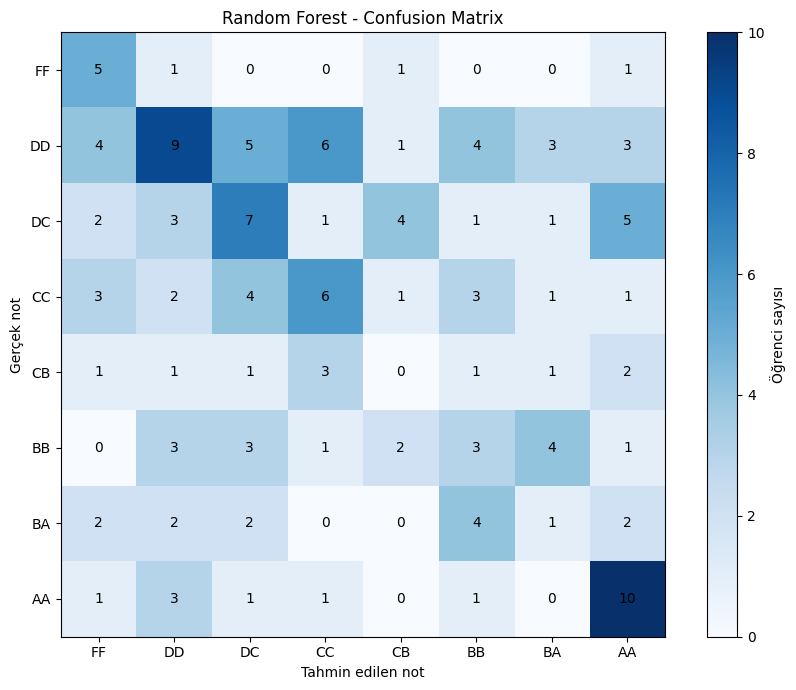

In [193]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 7))

plt.imshow(matris, cmap="Blues")
plt.colorbar(label="Öğrenci sayısı")

plt.xticks(range(8), not_isimleri)
plt.yticks(range(8), not_isimleri)

plt.xlabel("Tahmin edilen not")
plt.ylabel("Gerçek not")
plt.title("Random Forest - Confusion Matrix")

for i in range(8):
    for j in range(8):
        plt.text(
            j, i, matris[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()
